# Does price buy quality? Wine critics' scores, prices, review text and lab chemistry
Two complementary datasets:
* **130k Wine Enthusiast reviews:** critic score (80-100), price, country, variety, winery and the tasting note text.
* **UCI Wine Quality (Cortez et al., 2009):** 6,497 Portuguese *vinho verde* samples with 11 lab measurements and a sensory quality grade.

**Questions.** How much more quality does each extra dollar buy? Where are the "value" wines? Can the *words* in a review predict its score, and can lab chemistry predict quality?

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
import statsmodels.formula.api as smf
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error
w = pd.read_csv("data/wine_reviews_130k.csv.gz")
n0 = len(w); w = w.drop_duplicates(["title", "description"])
print(f"{n0:,} reviews, {n0 - len(w):,} exact duplicates removed -> {len(w):,}; price missing for {w.price.isna().mean():.1%}")
w.points.describe().round(2)

129,971 reviews, 9,983 exact duplicates removed -> 119,988; price missing for 7.0%


count    119988.00
mean         88.44
std           3.09
min          80.00
25%          86.00
50%          88.00
75%          91.00
max         100.00
Name: points, dtype: float64

each doubling of price is associated with +2.01 points (R² 0.38)


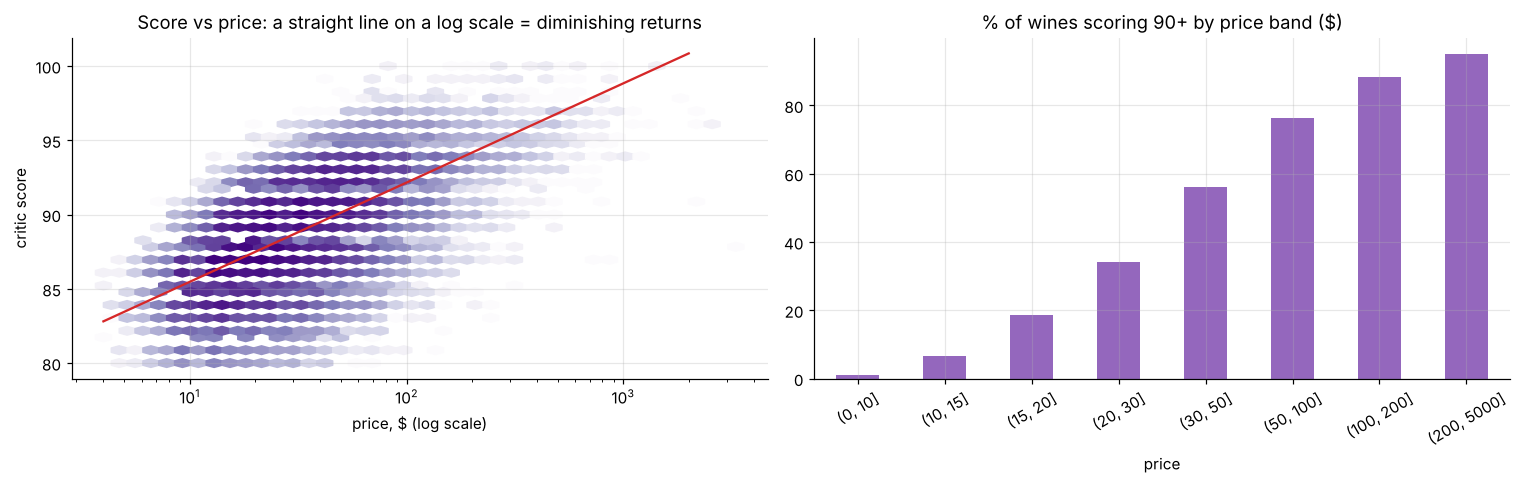

,wines,median_points,share_90_plus
price,,,
"(0, 10]",5916,85.0,1.2
"(10, 15]",17351,86.0,6.5
"(15, 20]",19480,87.0,18.6
"(20, 30]",24832,88.0,34.0
"(30, 50]",25534,90.0,56.1
"(50, 100]",15251,91.0,76.4
"(100, 200]",2564,93.0,88.3
"(200, 5000]",665,95.0,95.0


In [2]:
wp = w.dropna(subset=["price"]).copy(); wp["log2_price"] = np.log2(wp.price)
fit = smf.ols("points ~ log2_price", data=wp).fit()
print(f"each doubling of price is associated with +{fit.params['log2_price']:.2f} points (R² {fit.rsquared:.2f})")
bands = pd.cut(wp.price, [0, 10, 15, 20, 30, 50, 100, 200, 5000])
tab = wp.groupby(bands, observed=True).agg(wines=("points", "size"), median_points=("points", "median"), share_90_plus=("points", lambda p: (p >= 90).mean() * 100))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hexbin(wp.price, wp.points, gridsize=40, xscale="log", bins="log", cmap="Purples")
xs = np.logspace(np.log10(4), np.log10(2000)); axes[0].plot(xs, fit.params.Intercept + fit.params.log2_price * np.log2(xs), "C3")
axes[0].set_xlabel("price, $ (log scale)"); axes[0].set_ylabel("critic score"); axes[0].set_title("Score vs price: a straight line on a log scale = diminishing returns")
(tab.share_90_plus).plot.bar(ax=axes[1], rot=30, color="C4", title="% of wines scoring 90+ by price band ($)")
plt.tight_layout(); plt.savefig(IMG / "price_points.png", bbox_inches="tight"); plt.show()
tab.round(1)

## Value for money
A wine's **value score** is its rating minus the rating its price predicts. Grouping by variety and country shows where buyers get the most quality per dollar (groups with at least 300 priced reviews).

In [3]:
wp["value"] = fit.resid
grp = wp.groupby(["country", "variety"]).agg(reviews=("points", "size"), median_price=("price", "median"), mean_points=("points", "mean"), value=("value", "mean"))
grp = grp[grp.reviews >= 300].sort_values("value", ascending=False)
display(grp.head(6).round(2)); grp.tail(4).round(2)

,,reviews,median_price,mean_points,value
country,variety,,,,
Austria,Riesling,469,31.0,91.51,2.51
France,Riesling,584,29.0,90.74,2.15
Austria,Grüner Veltliner,924,23.0,90.20,2.12
Portugal,Portuguese Red,2028,17.0,88.90,1.52
France,Malbec,373,24.0,89.73,1.47
Germany,Riesling,1615,28.0,90.12,1.36


reviews  median_price  mean_points  value
country variety                                               
US      Sangiovese       396          26.0        87.18  -1.07
        Tempranillo      315          30.0        87.60  -1.12
Chile   Pinot Noir       334          16.0        85.86  -1.19
        Chardonnay       480          13.0        85.10  -1.34

## Can the review text predict the score?
TF-IDF of the tasting note (words and two-word phrases) into a ridge regression, scored on a 20% hold-out. Price and variety are deliberately excluded, so this measures how much the *words alone* reveal.

text-only model: R² 0.698, mean abs error 1.34 points (predicting the mean: 2.54)
correlation of review length with score: 0.52


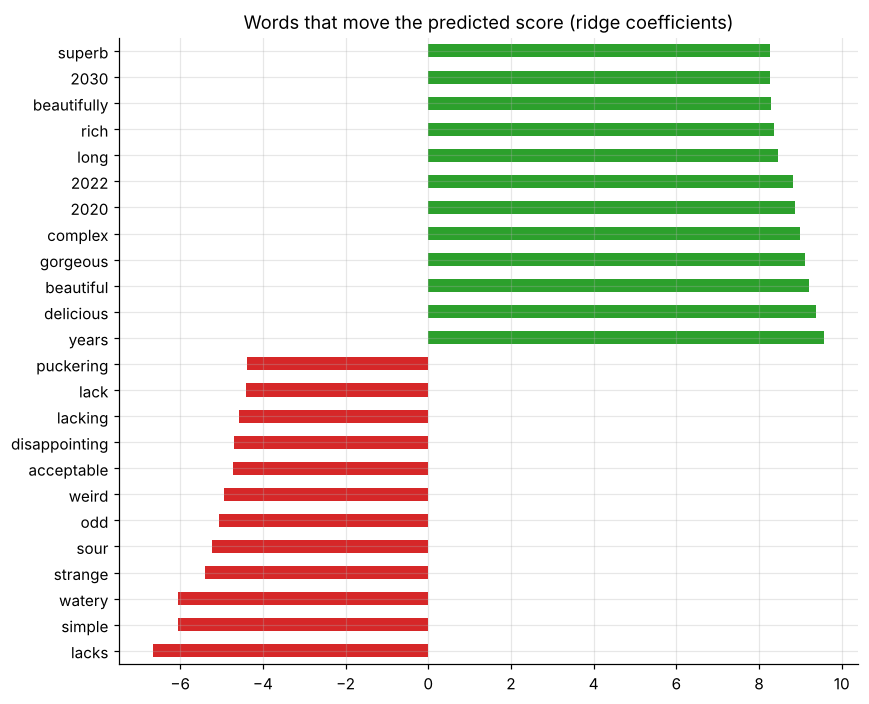

In [4]:
tr, te = train_test_split(w, test_size=0.2, random_state=0)
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.5, sublinear_tf=True, stop_words="english")
Xtr, Xte = vec.fit_transform(tr.description), vec.transform(te.description)
rg = Ridge(alpha=1.0).fit(Xtr, tr.points); pred = rg.predict(Xte)
print(f"text-only model: R² {r2_score(te.points, pred):.3f}, mean abs error {mean_absolute_error(te.points, pred):.2f} points (predicting the mean: {mean_absolute_error(te.points, np.full(len(te), tr.points.mean())):.2f})")
te_len = te.description.str.split().str.len()
print(f"correlation of review length with score: {np.corrcoef(te_len, te.points)[0, 1]:.2f}")
coef = pd.Series(rg.coef_, index=vec.get_feature_names_out())
words = pd.concat([coef.nsmallest(12), coef.nlargest(12)])
fig, ax = plt.subplots(figsize=(8, 6.5))
words.plot.barh(ax=ax, color=["C3"] * 12 + ["C2"] * 12); ax.set_title("Words that move the predicted score (ridge coefficients)")
plt.tight_layout(); plt.savefig(IMG / "review_words.png", bbox_inches="tight"); plt.show()

## Lab chemistry vs sensory quality (UCI vinho verde)

In [5]:
red = pd.read_csv("data/winequality_red.csv").assign(colour="red"); white = pd.read_csv("data/winequality_white.csv").assign(colour="white")
q = pd.concat([red, white], ignore_index=True); q["is_red"] = (q.colour == "red").astype(int)
feats = [c for c in q.columns if c not in ("quality", "colour")]
cv = KFold(5, shuffle=True, random_state=0)
gb = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=0)
r2_gb = cross_val_score(gb, q[feats], q.quality, cv=cv, scoring="r2").mean()
lin = smf.ols("quality ~ " + " + ".join(f"Q('{c}')" for c in feats), data=q).fit()
print(f"{len(q):,} samples; quality grades {sorted(int(x) for x in q.quality.unique())}; linear R² {lin.rsquared:.2f}; gradient boosting CV R² {r2_gb:.2f}")
corr = q[feats + ["quality"]].corr()["quality"].drop("quality").sort_values()
corr.round(3).to_frame("correlation with quality")

6,497 samples; quality grades [3, 4, 5, 6, 7, 8, 9]; linear R² 0.30; gradient boosting CV R² 0.49


,correlation with quality
density,-0.306
volatile acidity,-0.266
chlorides,-0.201
is_red,-0.119
fixed acidity,-0.077
total sulfur dioxide,-0.041
residual sugar,-0.037
pH,0.020
sulphates,0.038
free sulfur dioxide,0.055


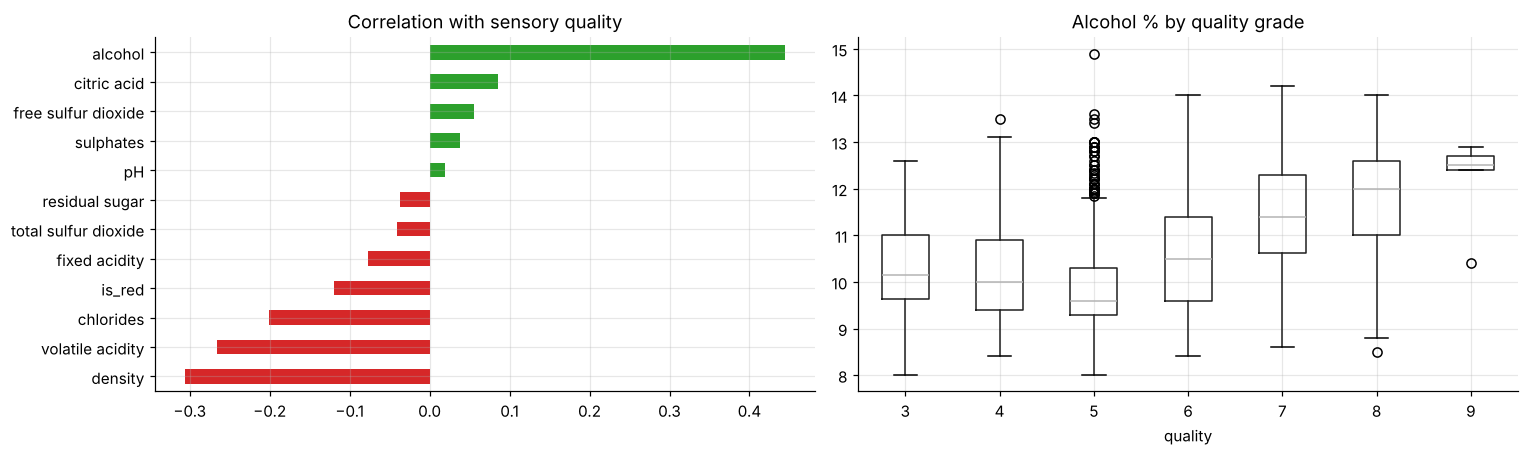

{3: 10.15, 4: 10.0, 5: 9.6, 6: 10.5, 7: 11.4, 8: 12.0, 9: 12.5}

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
corr.plot.barh(ax=axes[0], color=np.where(corr > 0, "C2", "C3"), title="Correlation with sensory quality")
q.boxplot("alcohol", by="quality", ax=axes[1]); axes[1].set_title("Alcohol % by quality grade"); plt.suptitle("")
plt.tight_layout(); plt.savefig(IMG / "chemistry.png", bbox_inches="tight"); plt.show()
q.groupby("quality").alcohol.median().round(2).to_dict()

## Findings
* **Price does buy points, with steeply diminishing returns.** Each *doubling* of price is associated with about +2 points (R² 0.38). Only 1% of wines at $10 or less score 90+, against 56% at $30-50 and 95% above $200. The jump from $50-100 to $100-200 buys only 2 extra median points (91 to 93).
* **Value pockets:** Austrian and French Riesling, Austrian Grüner Veltliner and Portuguese reds score 1.5-2.5 points above what their price predicts. US Sangiovese and Tempranillo and Chilean Pinot Noir and Chardonnay score about 1-1.3 points below.
* **The words reveal the score.** A text-only model (no price, variety or country) explains **70%** of score variation, with a mean error of 1.3 points against 2.5 for guessing the average. "Years", "delicious", "beautiful", "complex" and future drinking-window years (2020-2030, a sign of a wine worth cellaring) push scores up; "lacks", "simple", "watery", "strange" and "sour" push them down. Longer notes go with higher scores (r = 0.52), since critics write more about wines they like.
* **Chemistry predicts quality only partly:** gradient boosting reaches a cross-validated R² of 0.49 on 6,497 vinho verde samples (linear 0.30). Alcohol is by far the strongest correlate (r = 0.44; median 9.6% at grade 5 vs 12.0% at grade 8), followed by lower density and lower volatile acidity. Much of what tasters reward is not in a standard lab panel.
* **Caveat:** 9,983 duplicate reviews were removed first. Critics review the wines they are sent, so the price-score link describes the reviewed market, not every bottle on a shelf.